In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import RobustScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, DBSCAN
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score
from sklearn.neighbors import NearestNeighbors

from scipy.cluster.hierarchy import linkage, dendrogram, fcluster


In [2]:
POLLUTANTS = ["pm25", "pm10"]
LAGGED_DAYS = (1, 2, 3)
ROLLING_WINDOWS = (3, 7)
MAX_CLUSTERS = 8

WINTER_SHARE_THRESHOLD = 0.6
DBSCAN_MIN_SAMPLES_CANDIDATES = [5, 8, 10, 15, 20]

SEASONS = ["winter", "spring", "summer", "autumn"]
SEASON_MAP = {
    12: "winter", 1: "winter", 2: "winter",
    3: "spring", 4: "spring", 5: "spring",
    6: "summer", 7: "summer", 8: "summer",
    9: "autumn", 10: "autumn", 11: "autumn",
}


In [3]:
PROCESSED_DIR = Path("../data/processed")


In [4]:
def build_cluster_matrix(df, pollutant):
    lag_cols = [f"{pollutant}_lag_{d}" for d in LAGGED_DAYS]
    rolling_cols = [f"{pollutant}_rolling_{w}" for w in ROLLING_WINDOWS]
    rolling_std_cols = [f"{pollutant}_rolling_std_{w}" for w in ROLLING_WINDOWS]
    calendar_cols = ["month_sin", "month_cos", "dow_sin", "dow_cos"]
    weather_cols = [
        "temperature_2m_mean",
        "relative_humidity_2m_mean",
        "wind_speed_10m_mean",
        "precipitation_sum",
        "pressure_msl_mean",
    ]

    base_cols = lag_cols + rolling_cols + rolling_std_cols + calendar_cols + weather_cols + ["rain_indicator", "is_weekend"]
    required = base_cols + ["date", "station_id", pollutant]
    cluster_df = df.dropna(subset=required).copy().reset_index(drop=True)

    wind_dummies = pd.get_dummies(cluster_df["wind_category"], prefix="wind")
    X_cont = RobustScaler().fit_transform(cluster_df[base_cols])
    X = pd.concat([
        pd.DataFrame(X_cont, columns=base_cols),
        wind_dummies.reset_index(drop=True),
    ], axis=1)

    return cluster_df, X


In [5]:
runs = {}

for pollutant in POLLUTANTS:
    df = pd.read_parquet(PROCESSED_DIR / f"features_{pollutant}.parquet")
    df["date"] = pd.to_datetime(df["date"])
    df = df.sort_values("date").reset_index(drop=True)

    cluster_df, X = build_cluster_matrix(df, pollutant)

    pca = PCA(n_components=0.90, random_state=42)
    X_pca = pca.fit_transform(X)

    print(f"{pollutant.upper()}: {len(cluster_df):,} rows | input features: {X.shape[1]} | "
          f"PCA components: {X_pca.shape[1]} ({pca.explained_variance_ratio_.sum():.1%} variance kept)")

    runs[pollutant] = {"cluster_df": cluster_df, "X": X, "X_pca": X_pca}


PM25: 1,888 rows | input features: 21 | PCA components: 2 (92.6% variance kept)
PM10: 3,575 rows | input features: 21 | PCA components: 3 (91.8% variance kept)


In [6]:
def scan_k_values(X_pca, pollutant):
    ks = range(2, MAX_CLUSTERS + 1)
    inertias = []
    silhouettes = []

    for k in ks:
        km = KMeans(n_clusters=k, random_state=42, n_init=10).fit(X_pca)
        inertias.append(km.inertia_)
        silhouettes.append(silhouette_score(X_pca, km.labels_))

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    axes[0].plot(list(ks), inertias, marker="o")
    axes[0].set_xlabel("Number of clusters")
    axes[0].set_ylabel("Inertia (within-cluster SSE)")
    axes[0].set_title(f"Elbow method - {pollutant.upper()}")

    axes[1].plot(list(ks), silhouettes, marker="o")
    axes[1].set_xlabel("Number of clusters")
    axes[1].set_ylabel("Silhouette score")
    axes[1].set_title(f"Silhouette score - {pollutant.upper()}")

    plt.tight_layout()
    plt.show()

    return {"ks": list(ks), "inertias": inertias, "silhouettes": silhouettes}



PM25


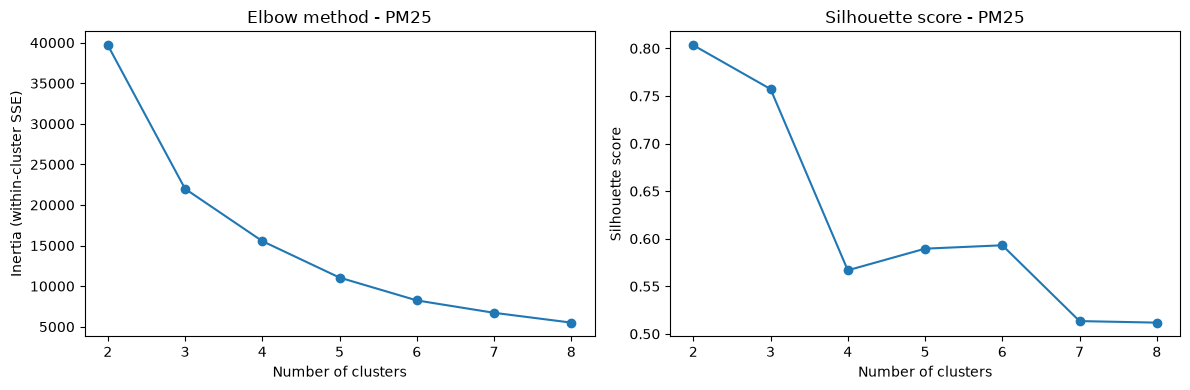


PM10


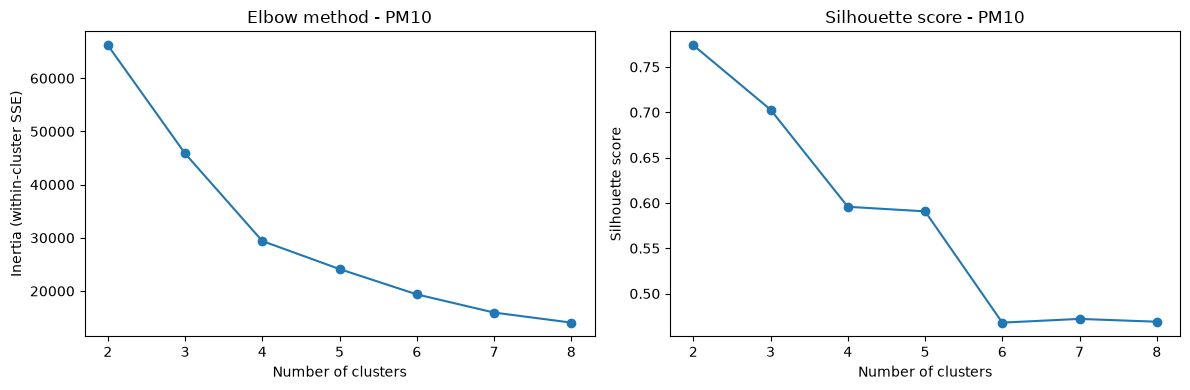

In [7]:
for pollutant in POLLUTANTS:
    print(f"\n{pollutant.upper()}")
    runs[pollutant].update(scan_k_values(runs[pollutant]["X_pca"], pollutant))


In [8]:
def scan_regimes(cluster_df, X_pca, pollutant, ks):
    regime_scan = []

    for k in ks:
        km = KMeans(n_clusters=k, random_state=42, n_init=10).fit(X_pca)
        labels = km.labels_
        tmp = cluster_df.assign(c=labels)
        pm_by_cluster = tmp.groupby("c")[pollutant].mean()
        top_idx = pm_by_cluster.idxmax()
        top_mask = tmp["c"] == top_idx
        winter_share = tmp.loc[top_mask, "date"].dt.month.map(SEASON_MAP).eq("winter").mean()
        regime_scan.append({
            "k": k,
            "silhouette": silhouette_score(X_pca, labels),
            "top_cluster_size": int(top_mask.sum()),
            "top_pm_mean": round(float(pm_by_cluster.loc[top_idx]), 1),
            "top_winter_share": round(float(winter_share), 2),
        })

    return pd.DataFrame(regime_scan)


In [9]:
for pollutant in POLLUTANTS:
    entry = runs[pollutant]
    scan_df = scan_regimes(entry["cluster_df"], entry["X_pca"], pollutant, entry["ks"])
    entry["scan_df"] = scan_df

    display(scan_df)

    silhouette_best_k = int(entry["ks"][int(np.argmax(entry["silhouettes"]))])
    winter_candidates = scan_df.loc[scan_df["top_winter_share"] >= WINTER_SHARE_THRESHOLD]
    best_k = int(winter_candidates["k"].min()) if len(winter_candidates) else silhouette_best_k
    entry["best_k"] = best_k

    print(f"\n{pollutant.upper()} — silhouette-best k: {silhouette_best_k}")
    print(f"Chosen k: {best_k} (smallest k whose highest-pollution cluster is winter-dominant; "
          f"silhouette alone favours {silhouette_best_k}, a dense season-neutral catch-all cluster)")


,k,silhouette,top_cluster_size,top_pm_mean,top_winter_share
0,2,0.803361,1722,25.7,0.29
1,3,0.757270,1656,26.0,0.30
2,4,0.566811,354,51.0,0.81
3,5,0.589560,345,50.7,0.80
4,6,0.593111,345,50.7,0.80
5,7,0.513447,155,61.0,0.89
6,8,0.511834,165,60.8,0.90



PM25 — silhouette-best k: 2
Chosen k: 4 (smallest k whose highest-pollution cluster is winter-dominant; silhouette alone favours 2, a dense season-neutral catch-all cluster)


,k,silhouette,top_cluster_size,top_pm_mean,top_winter_share
0,2,0.773953,3275,48.6,0.26
1,3,0.702864,3177,49.1,0.26
2,4,0.595730,418,105.2,0.81
3,5,0.590682,413,105.5,0.81
4,6,0.467944,193,127.9,0.93
5,7,0.472043,193,127.9,0.93
6,8,0.468950,193,127.9,0.93



PM10 — silhouette-best k: 2
Chosen k: 4 (smallest k whose highest-pollution cluster is winter-dominant; silhouette alone favours 2, a dense season-neutral catch-all cluster)


In [10]:
def tune_dbscan(X_pca, pollutant):
    fig, ax = plt.subplots(figsize=(7, 4))
    for ms in DBSCAN_MIN_SAMPLES_CANDIDATES:
        nn = NearestNeighbors(n_neighbors=ms).fit(X_pca)
        dist, _ = nn.kneighbors(X_pca)
        ax.plot(np.sort(dist[:, -1]), label=f"min_samples={ms}")
    ax.set_xlabel("point index (sorted by k-th neighbour distance)")
    ax.set_ylabel("k-th nearest neighbour distance")
    ax.set_title(f"DBSCAN: k-distance curves - {pollutant.upper()}")
    ax.legend()
    plt.tight_layout()
    plt.show()

    grid_results = []
    for ms in DBSCAN_MIN_SAMPLES_CANDIDATES:
        for eps in np.arange(0.3, 1.51, 0.05):
            labels = DBSCAN(eps=eps, min_samples=ms).fit_predict(X_pca)
            n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
            noise_frac = (labels == -1).mean()
            if noise_frac > 0.15 or not (2 <= n_clusters <= 6):
                continue
            sil = silhouette_score(X_pca[labels != -1], labels[labels != -1])
            score = sil - 0.30 * noise_frac
            grid_results.append({"eps": eps, "min_samples": ms, "silhouette": sil,
                                 "n_clusters": n_clusters, "noise_frac": noise_frac,
                                 "score": score})

    best_dbscan = max(grid_results, key=lambda r: r["score"])
    print(f"DBSCAN grid search: eps={best_dbscan['eps']:.2f}, min_samples={best_dbscan['min_samples']} "
          f"-> {best_dbscan['n_clusters']} clusters, {best_dbscan['noise_frac']:.1%} noise, "
          f"silhouette={best_dbscan['silhouette']:.3f}")

    return best_dbscan



PM25


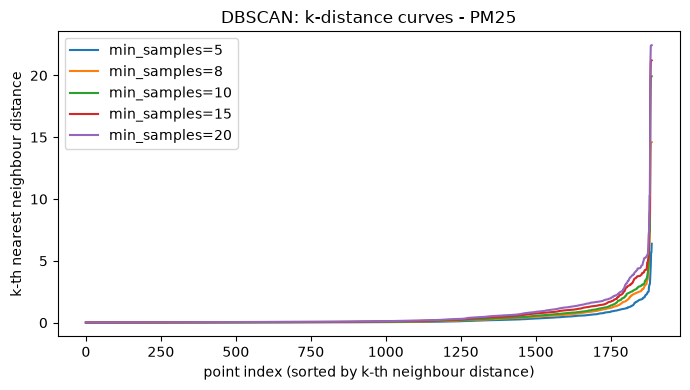

DBSCAN grid search: eps=1.35, min_samples=15 -> 3 clusters, 6.8% noise, silhouette=0.758

PM10


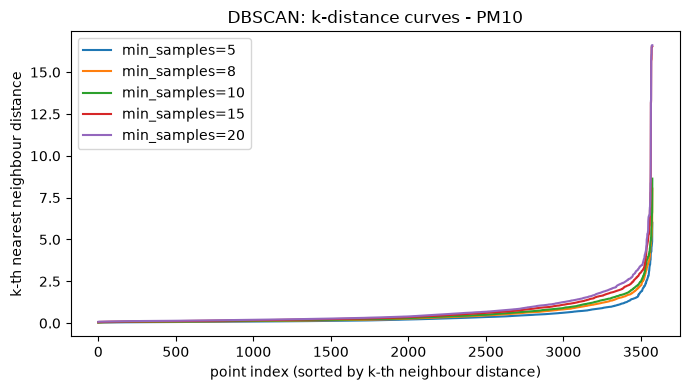

DBSCAN grid search: eps=1.40, min_samples=10 -> 4 clusters, 5.4% noise, silhouette=0.777


In [11]:
for pollutant in POLLUTANTS:
    print(f"\n{pollutant.upper()}")
    runs[pollutant]["dbscan"] = tune_dbscan(runs[pollutant]["X_pca"], pollutant)


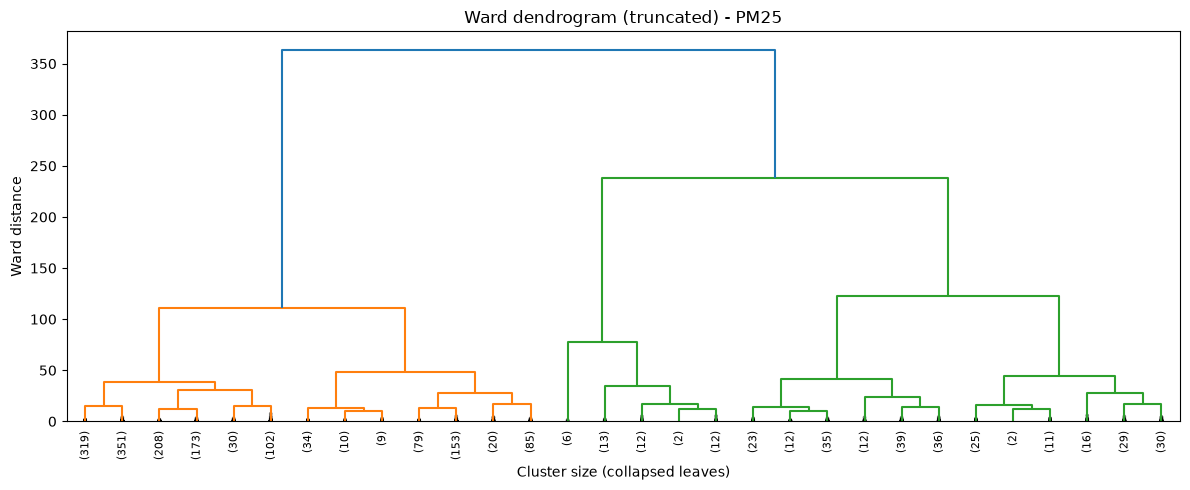

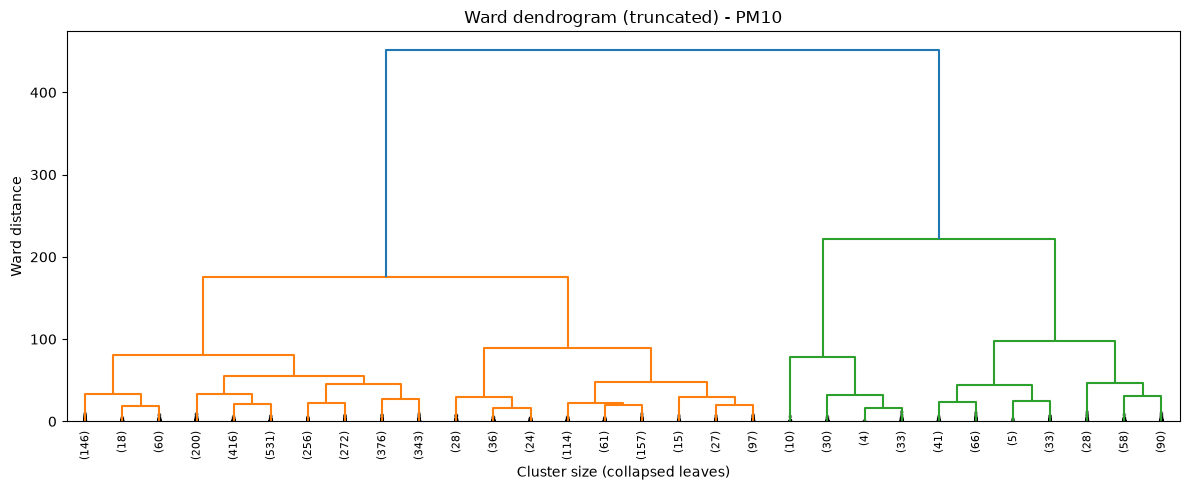

In [12]:
for pollutant in POLLUTANTS:
    entry = runs[pollutant]
    entry["hc_linkage"] = linkage(entry["X_pca"], method="ward")

    plt.figure(figsize=(12, 5))
    dendrogram(entry["hc_linkage"], truncate_mode="lastp", p=30, show_contracted=True,
               leaf_rotation=90.0, leaf_font_size=8.0)
    plt.title(f"Ward dendrogram (truncated) - {pollutant.upper()}")
    plt.xlabel("Cluster size (collapsed leaves)")
    plt.ylabel("Ward distance")
    plt.tight_layout()
    plt.show()


In [13]:
for pollutant in POLLUTANTS:
    entry = runs[pollutant]
    best_k = entry["best_k"]

    kmeans = KMeans(n_clusters=best_k, random_state=42, n_init=10)
    gmm = GaussianMixture(n_components=best_k, random_state=42)
    dbscan = DBSCAN(eps=entry["dbscan"]["eps"], min_samples=entry["dbscan"]["min_samples"])

    kmeans_labels = kmeans.fit_predict(entry["X_pca"])
    gmm_labels = gmm.fit_predict(entry["X_pca"])
    dbscan_labels = dbscan.fit_predict(entry["X_pca"])
    hierarchical_labels = fcluster(entry["hc_linkage"], t=best_k, criterion="maxclust")

    entry["cluster_df"]["cluster_kmeans"] = kmeans_labels
    entry["cluster_df"]["cluster_gmm"] = gmm_labels
    entry["cluster_df"]["cluster_dbscan"] = dbscan_labels
    entry["cluster_df"]["cluster_hierarchical"] = hierarchical_labels

    sil_kmeans = silhouette_score(entry["X_pca"], kmeans_labels)
    sil_gmm = silhouette_score(entry["X_pca"], gmm_labels)
    sil_dbscan = silhouette_score(entry["X_pca"][dbscan_labels != -1], dbscan_labels[dbscan_labels != -1])
    sil_hier = silhouette_score(entry["X_pca"], hierarchical_labels)

    print(f"\n{pollutant.upper()} (k={best_k})")
    print(f"Silhouette K-Means     : {sil_kmeans:.3f}")
    print(f"Silhouette GMM         : {sil_gmm:.3f}")
    print(f"Silhouette DBSCAN      : {sil_dbscan:.3f}")
    print(f"Silhouette Hierarchical: {sil_hier:.3f}")



PM25 (k=4)
Silhouette K-Means     : 0.567
Silhouette GMM         : 0.213
Silhouette DBSCAN      : 0.758
Silhouette Hierarchical: 0.630



PM10 (k=4)
Silhouette K-Means     : 0.596
Silhouette GMM         : 0.246
Silhouette DBSCAN      : 0.777
Silhouette Hierarchical: 0.540


In [14]:
def describe_clusters(frame, label_col, pollutant):
    frame = frame.copy()
    frame[label_col] = frame[label_col].map(lambda v: "-1 (noise)" if v == -1 else str(v))
    frame["month"] = frame["date"].dt.month
    frame["season"] = frame["month"].map(SEASON_MAP)

    summary = (
        frame.groupby(label_col)
        .agg(count=("station_id", "size"),
             pm_mean=(pollutant, "mean"),
             mean_month=("month", "mean"),
             n_stations=("station_id", "nunique"))
        .reset_index()
    )

    season_counts = frame.groupby([label_col, "season"]).size().reset_index(name="n")
    season_counts["share"] = season_counts["n"] / season_counts.groupby(label_col)["n"].transform("sum")
    season_shares = (
        season_counts.pivot(index=label_col, columns="season", values="share")
        .reindex(columns=SEASONS)
        .fillna(0.0)
        .add_prefix("share_")
        .reset_index()
    )

    summary = summary.merge(season_shares, on=label_col, how="left")
    summary["mean_month"] = summary["mean_month"].round(1)
    summary["top_season"] = summary[[f"share_{s}" for s in SEASONS]].idxmax(axis=1).str.replace("share_", "")
    return summary


In [15]:
summaries = {}

for pollutant in POLLUTANTS:
    summaries[pollutant] = {}

    for label_col in ["cluster_kmeans", "cluster_gmm", "cluster_dbscan", "cluster_hierarchical"]:
        print(f"\n{pollutant.upper()} — {label_col}")
        summary = describe_clusters(runs[pollutant]["cluster_df"], label_col, pollutant)
        summaries[pollutant][label_col] = summary
        display(summary)



PM25 — cluster_kmeans


,cluster_kmeans,count,pm_mean,mean_month,n_stations,share_winter,share_spring,share_summer,share_autumn,top_season
0,0,1302,19.255349,7.1,5,0.156682,0.218894,0.366359,0.258065,summer
1,1,187,17.411839,7.4,5,0.224599,0.229947,0.122995,0.422460,autumn
2,2,45,13.070466,8.2,5,0.111111,0.355556,0.022222,0.511111,autumn
3,3,354,50.969308,6.9,5,0.807910,0.053672,0.019774,0.118644,winter



PM25 — cluster_gmm


,cluster_gmm,count,pm_mean,mean_month,n_stations,share_winter,share_spring,share_summer,share_autumn,top_season
0,0,579,14.119739,7.2,5,0.055268,0.158895,0.613126,0.172712,summer
1,1,339,22.983166,6.8,5,0.286136,0.221239,0.209440,0.283186,winter
2,2,314,18.057341,7.7,5,0.213376,0.267516,0.089172,0.429936,autumn
3,3,656,38.599325,6.9,5,0.519817,0.170732,0.082317,0.227134,winter



PM25 — cluster_dbscan


...

,cluster_gmm,count,pm_mean,mean_month,n_stations,share_winter,share_spring,share_summer,share_autumn,top_season
0,0,2036,43.952737,7.0,5,0.197446,0.223477,0.299116,0.279961,summer
1,1,255,24.158209,7.5,5,0.086275,0.356863,0.145098,0.411765,autumn
2,2,390,38.020537,7.2,5,0.294872,0.233333,0.102564,0.369231,autumn
3,3,894,64.348358,6.4,5,0.411633,0.173378,0.176734,0.238255,winter



PM10 — cluster_dbscan


,cluster_dbscan,count,pm_mean,mean_month,n_stations,share_winter,share_spring,share_summer,share_autumn,top_season
0,-1 (noise),192,70.220038,6.1,5,0.666667,0.114583,0.031250,0.187500,winter
1,0,3343,46.022936,6.9,5,0.233024,0.227341,0.250673,0.288962,autumn
2,1,14,14.265185,10.1,5,0.000000,0.000000,0.000000,1.000000,autumn
3,2,11,13.099022,7.4,5,0.000000,0.454545,0.000000,0.545455,autumn
4,3,15,21.522119,7.9,5,0.000000,0.333333,0.000000,0.666667,autumn



PM10 — cluster_hierarchical


,cluster_hierarchical,count,pm_mean,mean_month,n_stations,share_winter,share_spring,share_summer,share_autumn,top_season
0,1,2618,39.324939,7.1,5,0.153552,0.252865,0.304049,0.289534,summer
1,2,559,95.001094,5.8,5,0.758497,0.046512,0.000000,0.194991,winter
2,3,77,20.390977,7.4,5,0.103896,0.402597,0.064935,0.428571,autumn
3,4,321,32.321339,7.4,5,0.227414,0.227414,0.133956,0.411215,autumn


In [16]:
for pollutant in POLLUTANTS:
    cluster_df = runs[pollutant]["cluster_df"]

    LABELS_OUT = PROCESSED_DIR / f"clustering_labels_{pollutant}.parquet"
    SUMMARY_COLS = ["station_id", "station_name", "date", pollutant, "cluster_kmeans", "cluster_gmm", "cluster_dbscan", "cluster_hierarchical"]

    cluster_df[SUMMARY_COLS].to_parquet(LABELS_OUT, index=False)

    summary_list = []
    for label_col, summary in summaries[pollutant].items():
        summary_list.append(summary.assign(method=label_col))

    summary_df = pd.concat(summary_list, ignore_index=True)
    summary_df.to_parquet(PROCESSED_DIR / f"clustering_summary_{pollutant}.parquet", index=False)

    print(f"Saved: clustering_labels_{pollutant}.parquet")
    print(f"Saved: clustering_summary_{pollutant}.parquet")


Saved: clustering_labels_pm25.parquet
Saved: clustering_summary_pm25.parquet
Saved: clustering_labels_pm10.parquet
Saved: clustering_summary_pm10.parquet
